# Demo: Event Summarization using SmolVLM

This notebook provides a demonstration for the second task of the assignment. Given the strong performance of vision-language models across a variety of tasks, we use an efficient, lightweight model: [SmolVLM 2](https://huggingface.co/blog/smolvlm2)
The goal of this notebook is to guide you on how to: design prompts for event detection, process model outputs, and evaluate the quality of detected events.
You are expected to build upon this baseline and critically evaluate your chosen approaches.

In [1]:
!pip install num2words
!pip install av
!pip install --upgrade transformers
!pip install opencv-python

In [2]:
import requests
import os
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch
import cv2
from PIL import Image
import random
import json
import re
from datetime import datetime, timezone
from pathlib import Path

c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SmolVLM2 is a lightweight vision-language model designed for efficient video understanding with relatively few parameters. The material presented here is largely based on the original documentation and is intended to provide a starting point for developing your own approach.

In [ ]:
cache_path = r"C:\Users\Boop\.cache\huggingface\hub\models--HuggingFaceTB--SmolVLM2-2.2B-Instruct\snapshots\482adb537c021c86670beed01cd58990d01e72e4"

processor = AutoProcessor.from_pretrained(cache_path)
print("Processor loaded!")

✅ Processor loaded!


In [4]:
model_path = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
processor = AutoProcessor.from_pretrained(model_path)
model = AutoModelForImageTextToText.from_pretrained(
    model_path,
    torch_dtype=torch.bfloat16,
).to("cuda")

`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 2/2 [00:06<00:00,  3.44s/it]


Since SmolVLM2 is a vision-language model (VLM), you will need to design an appropriate prompt for the task. The prompt can be flexible and should be adapted based on the type of output you want (e.g., event lists, descriptions, or timestamps).

Vision-language models process visual inputs (such as frames or videos) together with text by encoding them into a shared representation space. The exact input format may vary across models.

In our case, the HuggingFace implementation handles most of the input preprocessing (e.g., frame sampling and formatting), allowing you to focus primarily on prompt design and output parsing.

In [ ]:
#load relative path to video_25.mp4
relative_path = os.path.join("..", "Moment-Retrieval-and-Video-Summarization", "TVSum", "video_25.mp4")
video_path = os.path.abspath(relative_path)
print(video_path)
print("File exists:", os.path.exists(video_path))

c:\Users\Boop\Workspace\ComputerVision\Moment-Retrieval-and-Video-Summarization\TVSum\video_25.mp4
File exists: True


In [ ]:
def save_generated_description(generated_text, file_path="generated_descriptions_trials.txt"):

    file_path = Path(file_path)

    text = generated_text[0] if isinstance(generated_text, list) else str(generated_text)

    # Split assistant response
    assistant_marker = "Assistant:"
    assistant_idx = text.rfind(assistant_marker)

    if assistant_idx != -1:
        prompt_part = text[:assistant_idx].strip()
        assistant_response = text[assistant_idx + len(assistant_marker):].strip()
    else:
        prompt_part = text.strip()
        assistant_response = ""

    # Try to extract only the prompt after the last "Frame from xx:xx\n\n"
    frame_matches = list(re.finditer(r":\n\n", prompt_part))
    if frame_matches:
        last_match = frame_matches[-1]
        prompt = prompt_part[last_match.end():].strip()
    else:
        prompt = prompt_part

    # Count frames analysed
    frames_analysed = len(re.findall(r"\nFrame from ", text))

    record = {
        "timestamp_saved": datetime.now(timezone.utc).isoformat(),
        "frames_analysed": frames_analysed,
        "prompt": prompt,
        "assistant_response": assistant_response        
    }

    with file_path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n\n")

    return record


def load_generated_descriptions(file_path="generated_descriptions_trials.txt"):
    """
    Load all saved description records from the JSONL file.
    """
    file_path = Path(file_path)
    if not file_path.exists():
        return []

    records = []
    with file_path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return records

In [7]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "video", "path": video_path},
            {"type": "text", "text": """Describe what is happening in the video, sequentially focusing on the most important events. 
             Describe the events in detail, including the people involved, their appearance, their actions, and any relevant context. 
             Avoid generic descriptions and focus on specific moments that stand out. 
             List the events in order of occurrence."""}
        ]
    },
    
]

inputs = processor.apply_chat_template(
    messages,
    num_frames=100,  # more frames = better coverage
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device, dtype=torch.bfloat16)

generated_ids = model.generate(
    **inputs,
    do_sample=False,
    max_new_tokens=512,
    repetition_penalty=1.3,      # penalises repeating the same phrases
    no_repeat_ngram_size=4,      # forbids repeating any 4-word sequence
)

generated_texts = processor.batch_decode(generated_ids, skip_special_tokens=True)
print(generated_texts[0])
save_generated_description(generated_texts[0])

c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\transformers\video_processing_utils.py:879: UserWarning: `torchcodec` is not installed and cannot be used to decode the video by default. Falling back to `torchvision`. Note that `torchvision` decoding is deprecated and will be removed in future versions. 
  warnings.warn(
c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\transformers\video_utils.py:524: UserWarning: Using `torchvision` for video decoding is deprecated and will be removed in future versions. Please use `torchcodec` instead.
  warnings.warn(
c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\torchvision\io\_video_deprecation_warning.py:5: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.war

User: You are provided the following series of one hundred frames from a 0:04:34 [H:MM:SS] video.

Frame from 00:01:
Frame from 00:03:
Frame from 00:06:
Frame from 00:09:
Frame from 00:11:
Frame from 00:14:
Frame from 00:17:
Frame from 00:20:
Frame from 00:22:
Frame from 00:25:
Frame from 00:28:
Frame from 00:31:
Frame from 00:33:
Frame from 00:36:
Frame from 00:39:
Frame from 00:42:
Frame from 00:44:
Frame from 00:47:
Frame from 00:50:
Frame from 00:53:
Frame from 00:55:
Frame from 00:58:
Frame from 01:01:
Frame from 01:04:
Frame from 01:06:
Frame from 01:09:
Frame from 01:12:
Frame from 01:15:
Frame from 01:17:
Frame from 01:20:
Frame from 01:23:
Frame from 01:26:
Frame from 01:28:
Frame from 01:31:
Frame from 01:34:
Frame from 01:37:
Frame from 01:39:
Frame from 01:42:
Frame from 01:45:
Frame from 01:48:
Frame from 01:50:
Frame from 01:53:
Frame from 01:56:
Frame from 01:59:
Frame from 02:01:
Frame from 02:04:
Frame from 02:07:
Frame from 02:10:
Frame from 02:12:
Frame from 02:15:
F

{'timestamp_saved': '2026-05-10T23:56:23.875292+00:00',
 'frames_analysed': 100,
 'prompt': 'Describe what is happening in the video, sequentially focusing on the most important events. \n             Describe the events in detail, including the people involved, their appearance, their actions, and any relevant context. \n             Avoid generic descriptions and focus on specific moments that stand out. \n             List the events in order of occurrence.',
 'assistant_response': "The video starts with an aerial view of a cityscape featuring tall buildings under overcast skies. A person wearing headphones takes photos while standing near graffiti-covered walls. They then walk through crowded streets before entering a building where they take more pictures inside. Next to them sits another individual holding up his camera for someone else's photo. Inside, two individuals sit at tables covered by red Coca Cola cans; later, we see this same table set outside against a backdrop of blu

The detected events are often highly descriptive, but they do not always capture the most important or salient moments in the video.

To address this, you may explore alternative strategies. One approach is to use a language model (LLM) to process frame-level descriptions generated from the video.

For example, you can experiment with randomly sampling frames from the video, generating descriptions for each frame using a vision-language model (VLM), and then aggregating these descriptions into a structured set of events using an LLM.


In [8]:
def sample_frames(video_path, num_frames):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames == 0:
        raise ValueError("Video has no frames.")

    frame_indices = sorted(random.sample(range(total_frames), min(num_frames, total_frames)))

    frames = []
    current_idx = 0
    target_idx_set = set(frame_indices)

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        if current_idx in target_idx_set:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(Image.fromarray(frame))

        current_idx += 1

    cap.release()
    return frames

In [9]:
frames = sample_frames(video_path, 4)
print(f"Got {len(frames)} frames")

Got 4 frames


In [10]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "url": frames[0]},
            {"type": "image", "url": frames[1]},
            {"type": "image", "url": frames[2]},
            {"type": "image", "url": frames[3]},
            {"type": "text", "text": "Describe the most relevant events in the video, list each event sequentially, using a numbered format. Describe it in terms of the actions different persons take"}
        ]
    },
]
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device, dtype=torch.bfloat16)

You may improve event detection by splitting the video into smaller temporal segments and prompting the VLM on each segment separately. The resulting partial event descriptions can then be combined into a single, coherent list using an LLM.

Crucially, you must define an evaluation scheme for event coverage, for example:
-How many annotated events are correctly detected?
-Which events are missed or incorrectly predicted?
-How does performance change with different prompting or segmentation strategies?

In [11]:
generated_ids = model.generate(**inputs, do_sample=False, max_new_tokens=256)

generated_texts = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True,
)

print(generated_texts[0])

User:















Describe the most relevant events in the video, list each event sequentially, using a numbered format. Describe it in terms of the actions different persons take
Assistant: In the first image, a person is standing on a bridge over a river, with a road and mountains in the background. The person is wearing a white shirt and is holding a camera.

In the second image, a cityscape is shown with tall buildings and a body of water in the background. The sky is clear and blue.

In the third image, a person is lying on a bed, holding a camera. The person is shirtless and wearing a green towel.


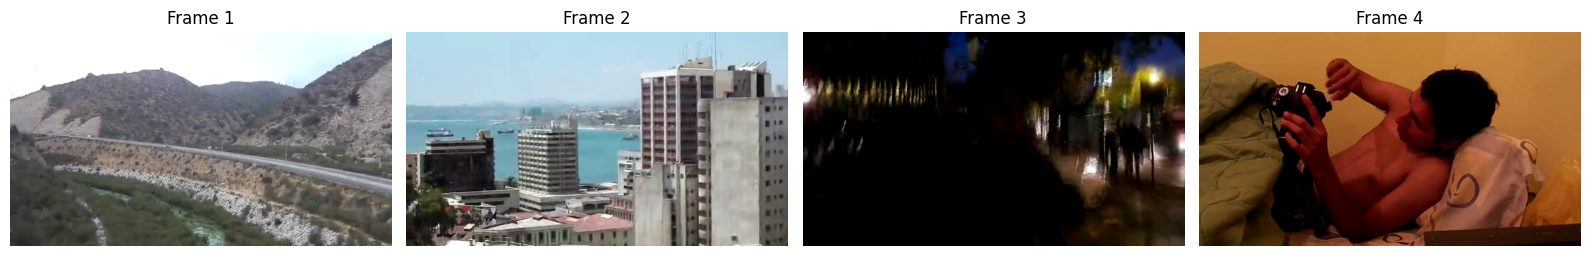

In [12]:
import matplotlib.pyplot as plt

n = len(frames)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))

if n == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.imshow(frames[i])
    ax.set_title(f"Frame {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

The generated outputs may be quite descriptive. While this can introduce noise, it also provides an opportunity to infer potential events through reasoning over these descriptions.

Therefore, one possible strategy is to first generate scene-level descriptions using a vision-language model (VLM), and then further process these descriptions using a language model (LLM) to extract structured events.

The choice of strategy is left to you. You are expected to design and implement an approach that produces meaningful event representations from the video.

In [13]:
def save_generated_annotation(events, file_path="generated_annotations_trials.txt"):

    file_path = Path(file_path)

    text = "\n".join(events) if isinstance(events, list) else str(events)

    record = {
        "timestamp_saved": datetime.now(timezone.utc).isoformat(),
        "annotation": text,
    }
    with file_path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

    return record

In [14]:
def extract_events_with_ollama(vlm_description, model="llama3.2"):
    
    prompt = f"""You are an expert video annotator. Below is a description of a video.
    Understand the overall context and narrative of the video based on the description provided.
Extract between 4 and 10 salient events from this description.

A salient event is important for understanding the overall narrative, clearly distinguishable, and described in 1-2 concise sentences. Don't narrate the flow of the video, just describe the events.

Format EXACTLY like this:
Salient event 1: [description]
Salient event 2: [description]
...
Only output the numbered list, nothing else.

Video description:
{vlm_description}"""

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={"model": model, "prompt": prompt, "stream": False}
    )
    
    return response.json()["response"]


def parse_salient_events(llm_output):
    events = []
    for line in llm_output.strip().splitlines():
        if not line.strip():
            continue

        # If line starts with "Salient event" keep text after first colon
        if ":" in line and line.lower().startswith("salient event"):
            description = line.split(":", 1)[1].strip()
        else:
            # remove leading "Salient event X" if present (with optional punctuation)
            description = re.sub(r"^\s*Salient event\s*\d+\s*[:\.\)\-]*\s*", "", line, flags=re.I)

            # remove leading numeric list markers like "1. ", "1) ", "1 - "
            description = re.sub(r"^\s*\d+\s*[:\.\)\-]*\s*", "", description)

        if description:
            events.append(description)
    return events


# paste your VLM description here
vlm_description = """The video starts with an aerial view of a cityscape featuring tall buildings under overcast skies. A person wearing headphones takes photos while standing near graffiti-covered walls. They then walk through crowded streets before entering a building where they take more pictures inside. Next to them sits another individual holding up his camera for someone else's photo. Inside, two individuals sit at tables covered by red Coca Cola cans; later, we see this same table set outside against a backdrop of blue sky and ocean waves. People gather around as boats pass nearby, suggesting it might be a beach or coastal area. Two men play soccer together outdoors amidst lush greenery. Later, three young boys engage in playful wrestling activities among colorful houses. An older man stands next to a large stone structure overlooking a bustling street filled with pedestrians walking past shops displaying various goods like clothing racks full of clothes hanging above storefronts. In front of these stores, several children run energetically along paved paths lined with trees. One child falls into water but quickly gets back onto dry land unharmed. A group gathers behind bars looking towards something offscreen. A woman holds her head down beside metal railings, possibly crying. A boy plays basketball indoors after taking selfies. Outside, a crowd watches intently as cars drive away during rush hour traffic congestion. A girl runs across a dirt path surrounded by green grass and bushes. A boat sails alongside rocky shores dotted with small structures resembling huts. A serene scene shows mountains rising majestically beneath clear skies. A train passes overhead carrying passengers dressed casually. A busy urban environment features towering high rises interspersed between smaller commercial establishments. A lively gathering unfolds atop a concrete wall adorned with vibrant murals depicting abstract designs. A shirtless man performs acrobatic flips midair within a fenced enclosure bordered by dense vegetation. A closeup reveals intricate details of ancient architecture nestled amongst verdant foliage. A scenic landscape showcases majestic mountain peaks bathed in soft sunlight filtering through wispy clouds. A panoramic shot captures a vast expanse of calm waters reflecting the surrounding scenery. A solitary figure walks alone on a bridge connecting distant lands separated by deep chasms. A picturesque town sprawls below, its quaint whitewashed facades contrasting beautifully with the azure sea beyond. A modern glass skyscraper looms prominently amid other architectural marvels. A tranquil harbor brimming with ships reflects upon itself gently. A sandy shore stretches endlessly toward the horizon, populated by numerous spectators watching a performance unfold. A festive atmosphere pervades as performers entertain crowds gathered closely together. A grand staircase leads"""

result = extract_events_with_ollama(vlm_description)
print(result)

events = parse_salient_events(result)
print("\n--- Parsed Events ---")
for i, event in enumerate(events, 1):
    print(f"{event}")

save_generated_annotation(events)

1. An aerial view of a cityscape featuring tall buildings under overcast skies.
2. A person wearing headphones takes photos while standing near graffiti-covered walls and then walks through crowded streets before entering a building where they take more pictures inside.
3. Two individuals sit at tables covered by red Coca Cola cans, later seen outside against a backdrop of blue sky and ocean waves.
4. People gather around as boats pass nearby, suggesting it might be a beach or coastal area.
5. A boy plays basketball indoors after taking selfies.
6. A group gathers behind bars looking towards something offscreen.
7. A woman holds her head down beside metal railings, possibly crying.
8. A shirtless man performs acrobatic flips midair within a fenced enclosure bordered by dense vegetation.
9. A panoramic shot captures a vast expanse of calm waters reflecting the surrounding scenery.
10. A sandy shore stretches endlessly toward the horizon, populated by numerous spectators watching a perfo

{'timestamp_saved': '2026-05-10T23:57:18.233095+00:00',
 'annotation': 'An aerial view of a cityscape featuring tall buildings under overcast skies.\nA person wearing headphones takes photos while standing near graffiti-covered walls and then walks through crowded streets before entering a building where they take more pictures inside.\nTwo individuals sit at tables covered by red Coca Cola cans, later seen outside against a backdrop of blue sky and ocean waves.\nPeople gather around as boats pass nearby, suggesting it might be a beach or coastal area.\nA boy plays basketball indoors after taking selfies.\nA group gathers behind bars looking towards something offscreen.\nA woman holds her head down beside metal railings, possibly crying.\nA shirtless man performs acrobatic flips midair within a fenced enclosure bordered by dense vegetation.\nA panoramic shot captures a vast expanse of calm waters reflecting the surrounding scenery.\nA sandy shore stretches endlessly toward the horizon,